In [21]:
from __future__ import annotations
from collections.abc import Sequence
from functools import total_ordering
from itertools import permutations
from math import cos, pi, sin
from random import sample

import matplotlib.pyplot as plt
from icecream import ic

ic.configureOutput(outputFunction=print)

NUM_CHILDREN = 10
NUM_CHARACTERISTICS = 20

In [22]:
@total_ordering
class Child:
    _name: str
    _characteristics: tuple[bool, ...]

    def __init__(self, name: str, characteristics: Sequence[bool]):
        self._name = name
        self._characteristics = tuple(characteristics)

    @property
    def name(self) -> str:
        return self._name

    def difference(self, other: Child) -> int:
        return sum(s != o for s, o in zip(self._characteristics, other._characteristics))

    def __repr__(self) -> str:
        return f"{self._name}:{''.join('+' if c else '-' for c in self._characteristics)}"

    def __eq__(self, other):
        return id(self) == id(other)

    def __lt__(self, other):
        return id(self) < id(other)


In [23]:
CHILDREN = list()

for c in range(NUM_CHILDREN):
    name = f"Child{c}"
    CHILDREN.append(
        Child(
            name,
            sample(
                [True, False], k=NUM_CHARACTERISTICS, counts=[NUM_CHARACTERISTICS, NUM_CHARACTERISTICS]
            ),
        )
    )

ic(CHILDREN)

ic| CHILDREN: [Child0:--++-++-++--+-+-+-+-,
               Child1:-++--+--+--+--+-++++,
               Child2:-+----+-+++++++----+,
               Child3:+-+-----+-++--+--+++,
               Child4:+-+-+----++++-+---+-,
               Child5:-+-++++++++-+-------,
               Child6:++-+-++---+-++-++-++,
               Child7:-+-++---++-+-+-++--+,
               Child8:+-+-+-+-+-+-----+-++,
               Child9:-++-+-+--+--+++-++-+]


[Child0:--++-++-++--+-+-+-+-,
 Child1:-++--+--+--+--+-++++,
 Child2:-+----+-+++++++----+,
 Child3:+-+-----+-++--+--+++,
 Child4:+-+-+----++++-+---+-,
 Child5:-+-++++++++-+-------,
 Child6:++-+-++---+-++-++-++,
 Child7:-+-++---++-+-+-++--+,
 Child8:+-+-+-+-+-+-----+-++,
 Child9:-++-+-+--+--+++-++-+]

In [24]:
def edges(solution: Sequence[Child]) -> list[tuple[Child, Child]]:
    circle = [CHILDREN[0]] + list(solution)
    return list(zip(circle, circle[1:] + circle[:1]))


def fitness(solution: Sequence[Child]) -> int:
    return sum(a.difference(b) for a, b in edges(solution))


def normalize(solution: Sequence[Child]) -> list[Child]:
    solution = list(solution)
    if solution[0] > solution[-1]:
        solution.reverse()
    return solution


def tweak(solution: Sequence[Child]) -> list[Child]:
    i1, i2 = sample(range(len(solution)), k=2)
    new_solution = list(solution)
    new_solution[i1] = solution[i2]
    new_solution[i2] = solution[i1]
    return normalize(new_solution)

def exhaustive_search() -> tuple[Child, ...]:
    return max(permutations(CHILDREN[1:]), key=fitness)


def hill_climbing(steps: int = 1000) -> tuple[list[Child], list[int]]:
    solution = normalize(sample(CHILDREN[1:], k=NUM_CHILDREN - 1))
    best = fitness(solution)
    history = [best]
    for _ in range(steps):
        candidate = tweak(solution)
        candidate_fitness = fitness(candidate)
        if candidate_fitness >= best:
            solution, best = candidate, candidate_fitness
        history.append(best)
    return solution, history

ic| title: 'Exhaustive search (guaranteed optimum)'
    order: ['Child0', 'Child2', 'Child8', 'Child9', 'Child3', 'Child5', 'Child1', 'Child6', 'Child4', 'Child7']
    distances: [10, 11, 10, 12, 15, 14, 12, 13, 13, 12]
    total: 122


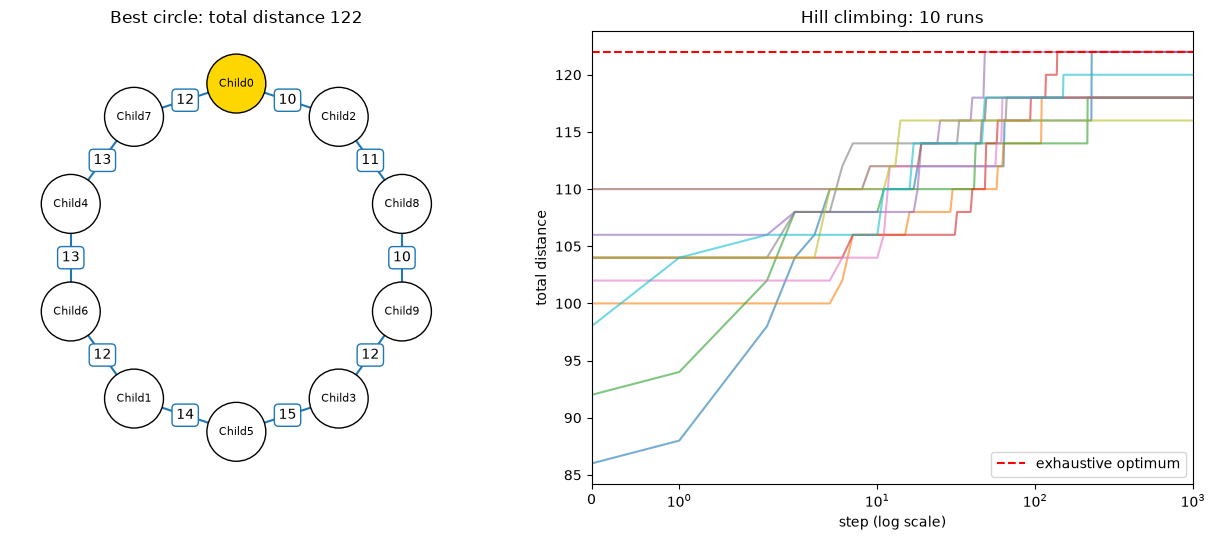

In [ ]:
def report(title: str, solution: Sequence[Child]) -> None:
    order = [a.name for a, _ in edges(solution)]
    distances = [a.difference(b) for a, b in edges(solution)]
    total = fitness(solution)
    ic(title, order, distances, total)

def plot_circle(ax, solution: Sequence[Child]) -> None:
    pairs = edges(solution)
    n = len(pairs)
    angles = [pi / 2 - 2 * pi * i / n for i in range(n)]
    xs = [cos(a) for a in angles]
    ys = [sin(a) for a in angles]
    for i, (a, b) in enumerate(pairs):
        j = (i + 1) % n
        ax.plot([xs[i], xs[j]], [ys[i], ys[j]], color="tab:blue", zorder=1)
        ax.text(
            (xs[i] + xs[j]) / 2,
            (ys[i] + ys[j]) / 2,
            a.difference(b),
            ha="center",
            va="center",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="tab:blue"),
            zorder=2,
        )
    ax.scatter(xs, ys, s=1800, c=["gold"] + ["white"] * (n - 1), edgecolors="black", zorder=3)
    for x, y, (a, _) in zip(xs, ys, pairs):
        ax.text(x, y, a.name, ha="center", va="center", fontsize=8, zorder=4)
    ax.set_title(f"Best circle: total distance {fitness(solution)}")
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.axis("off")


def plot_search(ax, histories: list[list[int]], optimum: Sequence[Child] | None) -> None:
    for history in histories:
        ax.plot(history, alpha=0.6)
    if optimum is not None:
        ax.axhline(fitness(optimum), color="red", linestyle="--", label="exhaustive optimum")
        ax.legend(loc="lower right")
    ax.set_xscale("symlog")
    ax.set_xlim(0, len(histories[0]))
    ax.set_xlabel("step (log scale)")
    ax.set_ylabel("total distance")
    ax.set_title(f"Hill climbing: {len(histories)} runs")


runs = [hill_climbing() for _ in range(10)]
histories = [history for _, history in runs]
climbed = max((solution for solution, _ in runs), key=fitness)
optimal = exhaustive_search() if NUM_CHILDREN <= 10 else None
answer = optimal if optimal is not None else climbed

if optimal is not None:
    report("Exhaustive search (guaranteed optimum)", optimal)
report("Hill climbing (best of 10 runs)", climbed)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))
plot_circle(left, answer)
plot_search(right, histories, optimal)
fig.tight_layout()
plt.show()